# Paper-inspired two-regime HMM: checkpointed results

This sweep runs GMM with 2 to 5 mixture components, with and without PCA, on a 5-year initial window. Run it from the project root:

```bash
PYTHONPATH=src:notebooks/sp500 .venv/bin/python notebooks/sp500/run_paper_regime.py --output notebooks/sp500/results/gmm_sweep_2004_2013 --models gmm2_pca gmm2_no_pca gmm3_pca gmm3_no_pca gmm4_pca gmm4_no_pca gmm5_pca gmm5_no_pca --years 5 --start 2004-01-02 --end 2013-12-31 --max-iter 100 --update-iter 3 --refresh-days 63
```

The script stores `checkpoint.pkl` (one trained HMM per spec, with its scaler and PCA, plus every completed decision) and `signals.csv` in that folder. Each row is one branch spec, such as `gmm3_no_pca`: emission family, GMM component count, and PCA setting. Rerun the same command to resume:

```bash
PYTHONPATH=src:notebooks/sp500 .venv/bin/python notebooks/sp500/run_paper_regime.py --output notebooks/sp500/results/paper_regime_2019_year --start 2019-01-02 --end 2019-12-30
```

The folder is gitignored. Checkpoints are Python pickle files: **load only checkpoints you created and trust**. Use a separate folder when changing training settings or data.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise FileNotFoundError("Run this notebook inside the project")
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "notebooks" / "sp500"))
from paper_regime_experiment import evaluate_signals
from model_evaluation.market_strategy.evaluation import compare_strategies
from model_evaluation.market_strategy.strategies import moving_average_timing

RESULT_DIR = ROOT / "notebooks/sp500/results/gmm_sweep_2004_2013"
signals_path = RESULT_DIR / "signals.csv"
if not signals_path.exists():
    raise FileNotFoundError(f"First run run_paper_regime.py; missing {signals_path}")
fits = pd.read_csv(signals_path, parse_dates=["date"])
prices = pd.read_csv(ROOT / "data/processed/sp500_index_price.csv",
                     parse_dates=["YYYYMMDD"]).set_index("YYYYMMDD")["DlyPrcInd"]
# One spec is one branch: emission, GMM components, and PCA setting, e.g. gmm3_no_pca.
SPEC_ORDER = sorted(fits.spec.unique(),
                    key=lambda name: (int(name.split("_")[0][3:]), name))
print("Saved dates:", fits.date.min().date(), "to", fits.date.max().date())
print("Decisions:", fits.date.nunique(), "specs:", len(SPEC_ORDER))
print("Specs:", SPEC_ORDER)
print("Refresh dates:", fits.loc[fits.refresh, "date"].nunique())
display(fits.groupby("spec")[["iterations", "training_days",
                              "n_components"]].agg(["mean", "max"]).round(1))

Saved dates: 2004-01-02 to 2013-12-31
Decisions: 2517 specs: 8
Specs: ['gmm2_no_pca', 'gmm2_pca', 'gmm3_no_pca', 'gmm3_pca', 'gmm4_no_pca', 'gmm4_pca', 'gmm5_no_pca', 'gmm5_pca']
Refresh dates: 40


iterations      training_days       n_components    
                  mean  max          mean   max         mean max
spec                                                            
gmm2_no_pca        3.1  100        2515.0  3773         28.0  28
gmm2_pca           2.4   65        2515.0  3773         10.0  10
gmm3_no_pca        3.1  100        2515.0  3773         28.0  28
gmm3_pca           2.8   83        2515.0  3773         10.0  10
gmm4_no_pca        3.2  100        2515.0  3773         28.0  28
gmm4_pca           3.1  100        2515.0  3773         10.0  10
gmm5_no_pca        3.1  100        2515.0  3773         28.0  28
gmm5_pca           3.2  100        2515.0  3773         10.0  10

,total_return,sharpe,max_drawdown,exposure,turnover_per_year
MA 50/200,0.917,0.541,-0.205,0.735,1.001
gmm3_pca,0.842,0.507,-0.208,0.578,5.406
gmm2_no_pca,0.932,0.506,-0.226,0.604,3.704
gmm4_no_pca,0.719,0.345,-0.327,0.567,3.604
gmm3_no_pca,0.535,0.279,-0.328,0.487,3.404
gmm2_pca,0.530,0.277,-0.319,0.593,5.406
Buy and hold,0.653,0.246,-0.568,1.000,0.000
gmm5_pca,0.227,0.191,-0.211,0.416,4.906
gmm5_no_pca,0.255,0.174,-0.400,0.533,3.004
gmm4_pca,0.179,0.110,-0.336,0.570,4.605


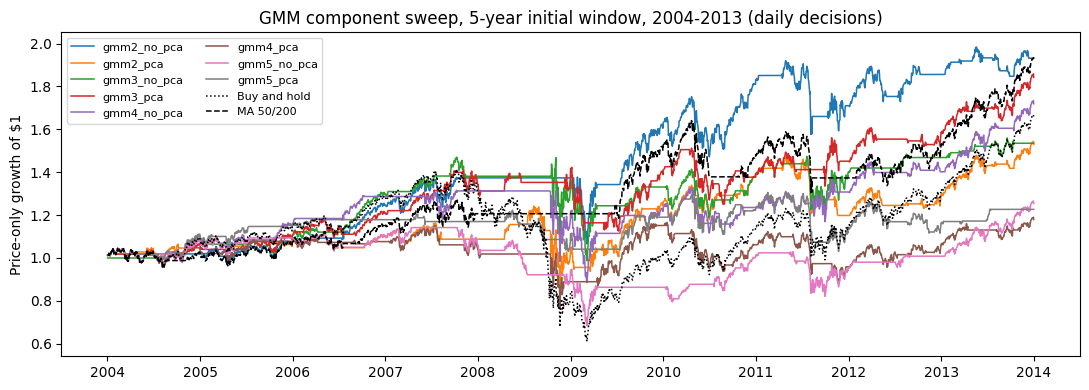

In [2]:
MEDIAN_WINDOW = 12
pnl, weights = {}, {}
# evaluate_signals groups by (model, pca), so call it once per spec.
for spec in SPEC_ORDER:
    spec_pnl, spec_weights = evaluate_signals(fits[fits.spec == spec], prices,
                                              median_window=MEDIAN_WINDOW)
    label = next(key for key in spec_pnl if key != "Buy and hold")
    pnl[spec], weights[spec] = spec_pnl[label], spec_weights[label]
    pnl["Buy and hold"], weights["Buy and hold"] = (spec_pnl["Buy and hold"],
                                                    spec_weights["Buy and hold"])
# moving_average_timing shifts internally: today's close sets tomorrow's position.
decision_dates = pd.DatetimeIndex(fits.date.drop_duplicates().sort_values())
next_dates = prices.index[prices.index.get_indexer(decision_dates) + 1]
ma_weights = moving_average_timing(prices, fast=50, slow=200).reindex(next_dates)
ma_weights.index = decision_dates
ma_returns = prices.pct_change(fill_method=None).reindex(next_dates)
pnl["MA 50/200"] = pd.Series(np.log1p(ma_weights.to_numpy() * ma_returns.to_numpy()),
                              index=ma_weights.index)
weights["MA 50/200"] = ma_weights
if fits.date.nunique() < 252:
    print("About one year or less: annualized estimates are noisy; interpret cautiously")
summary = compare_strategies(pnl, weights)
display(summary[["total_return", "sharpe", "max_drawdown", "exposure",
                 "turnover_per_year"]].round(3))
fig, ax = plt.subplots(figsize=(11, 4))
for spec in SPEC_ORDER:
    series = pnl[spec]
    ax.plot(series.index, np.exp(series.cumsum()), label=spec, linewidth=1.1)
for name in ("Buy and hold", "MA 50/200"):
    series = pnl[name]
    ax.plot(series.index, np.exp(series.cumsum()), label=name, linewidth=1.1,
            color="black", linestyle="--" if name == "MA 50/200" else ":")
ax.set(ylabel="Price-only growth of $1",
       title="GMM component sweep, 5-year initial window, 2004-2013 (daily decisions)")
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

In [3]:
rows = []
years = fits.date.nunique() / 252
for spec in SPEC_ORDER:
    group = fits[fits.spec == spec].sort_values("date")
    exposure = weights[spec].to_numpy()
    raw = group.bull_raw.to_numpy()
    rows.append({"spec": spec,
                 "gmm components": group.gmm_components.iloc[0],
                 "raw switches/year": np.count_nonzero(np.diff(raw)) / years,
                 "median switches/year": np.count_nonzero(np.diff(exposure)) / years,
                 "average days/position": len(raw) / (1 + np.count_nonzero(np.diff(exposure)))})
ma_exposure = weights["MA 50/200"].to_numpy()
ma_switches = np.count_nonzero(np.diff(ma_exposure))
rows.append({"spec": "MA 50/200", "gmm components": 0,
             "raw switches/year": ma_switches / years,
             "median switches/year": ma_switches / years,
             "average days/position": len(ma_exposure) / (1 + ma_switches)})
display(pd.DataFrame(rows).set_index("spec").round(2))

,gmm components,raw switches/year,median switches/year,average days/position
spec,,,,
gmm2_no_pca,2,8.41,3.70,66.24
gmm2_pca,2,11.01,5.41,45.76
gmm3_no_pca,3,8.51,3.40,71.91
gmm3_pca,3,11.61,5.41,45.76
gmm4_no_pca,4,7.41,3.60,68.03
gmm4_pca,4,12.21,4.61,53.55
gmm5_no_pca,5,5.81,3.00,81.19
gmm5_pca,5,11.41,4.91,50.34
MA 50/200,0,1.00,1.00,228.82
